# Measuring Alpha Decay Through Lagged Execution

In [28]:
import os
import numpy as np
import pandas as pd

In [42]:
path = r"A:\GitHub\SignalTrader\data\tmp.parquet"
df_signal = (pd
    .read_parquet(path = path, engine = "pyarrow")
    [["spx_rtn"]]
    .assign(
        R          = lambda x: x.spx_rtn / x.spx_rtn.ewm(span = 10, adjust = False).std(),
        signal     = lambda x: x.R.ewm(span = 50, adjust = False).mean(),
        lag_signal = lambda x: x.signal.shift()))

<Axes: xlabel='date'>

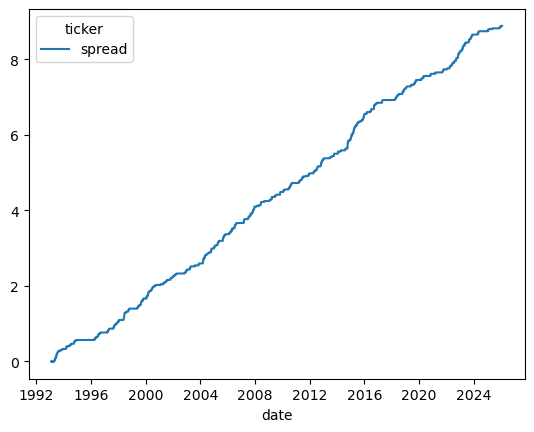

In [43]:
(df_signal
    .drop(columns = ["R"])
    .reset_index()
    .melt(id_vars = ["date", "spx_rtn"])
    .assign(signal_rtn = lambda x: np.sign(x.value) * x.spx_rtn)
    .pivot(index = "date", columns = "ticker", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .assign(spread = lambda x: x.signal - x.lag_signal)
    [["spread"]]
    .cumsum()
    .plot())